In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 150)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

RANDOM_STATE = 42

In [ ]:
DATA_DIR = Path("../data")

TRAIN_PATH = DATA_DIR / "train_test.csv"
VALIDATION_PATH = DATA_DIR / "validation.csv"

print("Train path:", TRAIN_PATH.resolve())
print("Validation path:", VALIDATION_PATH.resolve())

print("\nTrain exists:", TRAIN_PATH.exists())
print("Validation exists:", VALIDATION_PATH.exists())

Train path: C:\Users\youse\OneDrive\Desktop\ML ASS\data\train_test.csv
Validation path: C:\Users\youse\OneDrive\Desktop\ML ASS\data\validation.csv

Train exists: True
Validation exists: True


In [3]:
train = pd.read_csv(TRAIN_PATH)
validation = pd.read_csv(VALIDATION_PATH)

print("Data loaded successfully.")

print(f"\nTraining shape:   {train.shape}")
print(f"Validation shape: {validation.shape}")

Data loaded successfully.

Training shape:   (48000, 14)
Validation shape: (12000, 13)


In [4]:
train.head()

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09,-76.79,38.17,-72.75,274.30,Dry Van,"30,658.00",2025-01-01,0.96,2.40,645.41
1,TR-000002,Richmond,Philadelphia,38.09,-76.79,39.22,-72.97,280.50,Reefer,"17,555.00",2025-01-01,0.98,2.43,679.97
2,TR-000003,Philadelphia,Green Bay,39.22,-72.97,44.30,-87.53,967.80,Dry Van,"31,721.00",2025-01-01,1.01,1.84,"1,802.54"
3,TR-000004,Hartford,Atlanta,39.55,-72.18,34.85,-86.29,965.40,Dry Van,"32,333.00",2025-01-01,0.95,1.88,"1,827.28"
4,TR-000005,Dallas,Nashville,31.83,-94.38,35.29,-88.09,541.90,Reefer,"35,183.00",2025-01-01,0.98,2.56,"1,380.28"


In [5]:
validation.head()

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal
0,TE-000001,Baton Rouge,Mobile,30.50,-92.65,31.80,-88.25,331.40,Flatbed,"19,958.00",2025-11-01,0.90,1.86
1,TE-000002,Savannah,Los Angeles,33.61,-82.30,28.57,-116.70,"2,406.20",Reefer,"34,114.00",2025-11-01,0.93,1.86
2,TE-000003,San Francisco,Raleigh,35.20,-121.70,35.37,-77.48,"2,846.60",Dry Van,"33,435.00",2025-11-01,0.88,1.95
3,TE-000004,Dayton,Los Angeles,39.87,-85.63,28.57,-116.70,"2,261.60",Dry Van,"25,392.00",2025-11-01,0.89,2.15
4,TE-000005,Memphis,San Antonio,35.57,-89.53,29.51,-98.40,800.40,Flatbed,NaN,2025-11-01,0.88,2.23


In [6]:
print("TRAINING COLUMNS")
print("-" * 60)

for i, column in enumerate(train.columns, start=1):
    print(f"{i:2}. {column}")


print("\nVALIDATION COLUMNS")
print("-" * 60)

for i, column in enumerate(validation.columns, start=1):
    print(f"{i:2}. {column}")

TRAINING COLUMNS
------------------------------------------------------------
 1. load_id
 2. pickup
 3. delivery
 4. pickup_lat
 5. pickup_lon
 6. delivery_lat
 7. delivery_lon
 8. distance
 9. equipment
10. weight
11. date
12. market_index
13. quote_signal
14. posted_rate

VALIDATION COLUMNS
------------------------------------------------------------
 1. load_id
 2. pickup
 3. delivery
 4. pickup_lat
 5. pickup_lon
 6. delivery_lat
 7. delivery_lon
 8. distance
 9. equipment
10. weight
11. date
12. market_index
13. quote_signal


In [7]:
train_only = set(train.columns) - set(validation.columns)
validation_only = set(validation.columns) - set(train.columns)

print("Only in training:", train_only)
print("Only in validation:", validation_only)

Only in training: {'posted_rate'}
Only in validation: set()


In [8]:
#as we can see here same prediction features, with the target available only in development data and that what we need.

In [9]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48000 entries, 0 to 47999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   load_id       48000 non-null  object 
 1   pickup        48000 non-null  object 
 2   delivery      48000 non-null  object 
 3   pickup_lat    48000 non-null  float64
 4   pickup_lon    48000 non-null  float64
 5   delivery_lat  48000 non-null  float64
 6   delivery_lon  48000 non-null  float64
 7   distance      48000 non-null  float64
 8   equipment     48000 non-null  object 
 9   weight        47700 non-null  float64
 10  date          48000 non-null  object 
 11  market_index  47626 non-null  float64
 12  quote_signal  48000 non-null  float64
 13  posted_rate   48000 non-null  float64
dtypes: float64(9), object(5)
memory usage: 5.1+ MB


In [10]:
validation.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   load_id       12000 non-null  object 
 1   pickup        12000 non-null  object 
 2   delivery      12000 non-null  object 
 3   pickup_lat    12000 non-null  float64
 4   pickup_lon    12000 non-null  float64
 5   delivery_lat  12000 non-null  float64
 6   delivery_lon  12000 non-null  float64
 7   distance      12000 non-null  float64
 8   equipment     12000 non-null  object 
 9   weight        11835 non-null  float64
 10  date          12000 non-null  object 
 11  market_index  11751 non-null  float64
 12  quote_signal  12000 non-null  float64
dtypes: float64(8), object(5)
memory usage: 1.2+ MB


In [11]:
dtype_comparison = pd.DataFrame({
    "train_dtype": train.dtypes.astype(str),
    "validation_dtype": validation.dtypes.astype(str)
})

dtype_comparison

,train_dtype,validation_dtype
date,object,object
delivery,object,object
delivery_lat,float64,float64
delivery_lon,float64,float64
distance,float64,float64
equipment,object,object
load_id,object,object
market_index,float64,float64
pickup,object,object
pickup_lat,float64,float64


In [12]:
train.describe().T

,count,mean,std,min,25%,50%,75%,max
pickup_lat,"48,000.00",35.65,4.32,28.36,31.99,35.29,39.41,44.30
pickup_lon,"48,000.00",-90.93,13.48,-121.70,-98.40,-88.09,-83.29,-69.50
delivery_lat,"48,000.00",35.64,4.32,28.36,31.99,35.29,39.41,44.30
delivery_lon,"48,000.00",-90.86,13.48,-121.70,-98.40,-87.53,-83.29,-69.50
distance,"48,000.00","1,135.86",728.56,70.00,550.40,953.30,"1,645.53","3,439.80"
weight,"47,700.00","31,028.84","9,391.44","-47,500.00","25,800.00","31,436.50","37,018.00","47,500.00"
market_index,"47,626.00",1.08,0.17,0.68,0.95,1.06,1.22,1.47
quote_signal,"48,000.00",2.06,0.29,0.69,1.89,2.06,2.22,3.61
posted_rate,"48,000.00","2,373.98","1,486.49",57.22,"1,251.55","2,030.76","3,330.75","25,533.00"


In [13]:
validation.describe().T

,count,mean,std,min,25%,50%,75%,max
pickup_lat,"12,000.00",35.57,4.37,25.50,31.99,35.29,39.41,44.30
pickup_lon,"12,000.00",-90.72,13.41,-121.70,-97.23,-87.53,-82.78,-69.50
delivery_lat,"12,000.00",35.61,4.35,25.50,32.01,35.29,39.41,44.30
delivery_lon,"12,000.00",-90.91,13.62,-121.70,-98.40,-87.53,-82.78,-69.50
distance,"12,000.00","1,141.77",732.33,70.00,556.10,953.60,"1,670.50","3,325.70"
weight,"11,835.00","30,506.64","10,572.59","-47,500.00","25,493.00","31,193.00","36,843.50","47,500.00"
market_index,"11,751.00",0.93,0.07,0.72,0.86,0.92,0.99,1.10
quote_signal,"12,000.00",2.05,0.22,1.23,1.90,2.05,2.20,2.90


In [14]:
def missing_report(df):
    report = pd.DataFrame({
        "missing_count": df.isna().sum(),
        "missing_percent": df.isna().mean() * 100
    })

    return (
        report
        .sort_values("missing_count", ascending=False)
    )

In [15]:
print("Training missing values:")
print(train.isnull().sum())

print("\nValidation missing values:")
print(validation.isnull().sum())

Training missing values:
load_id           0
pickup            0
delivery          0
pickup_lat        0
pickup_lon        0
delivery_lat      0
delivery_lon      0
distance          0
equipment         0
weight          300
date              0
market_index    374
quote_signal      0
posted_rate       0
dtype: int64

Validation missing values:
load_id           0
pickup            0
delivery          0
pickup_lat        0
pickup_lon        0
delivery_lat      0
delivery_lon      0
distance          0
equipment         0
weight          165
date              0
market_index    249
quote_signal      0
dtype: int64


In [16]:
print("Training missing percentage:")

missing_percent = train.isnull().mean() * 100

print(missing_percent)

Training missing percentage:
load_id        0.00
pickup         0.00
delivery       0.00
pickup_lat     0.00
pickup_lon     0.00
delivery_lat   0.00
delivery_lon   0.00
distance       0.00
equipment      0.00
weight         0.62
date           0.00
market_index   0.78
quote_signal   0.00
posted_rate    0.00
dtype: float64


In [17]:
print("Duplicate training rows:", train.duplicated().sum())
print("Duplicate validation rows:", validation.duplicated().sum())

Duplicate training rows: 0
Duplicate validation rows: 0


In [18]:
print("Duplicate train IDs:", train["load_id"].duplicated().sum())
print("Duplicate validation IDs:", validation["load_id"].duplicated().sum())

Duplicate train IDs: 0
Duplicate validation IDs: 0


In [19]:
print("Missing rates:", train["posted_rate"].isnull().sum())
print("Zero rates:", (train["posted_rate"] == 0).sum())
print("Negative rates:", (train["posted_rate"] < 0).sum())

Missing rates: 0
Zero rates: 0
Negative rates: 0


In [20]:
train["posted_rate"].describe()

count   48,000.00
mean     2,373.98
std      1,486.49
min         57.22
25%      1,251.55
50%      2,030.76
75%      3,330.75
max     25,533.00
Name: posted_rate, dtype: float64

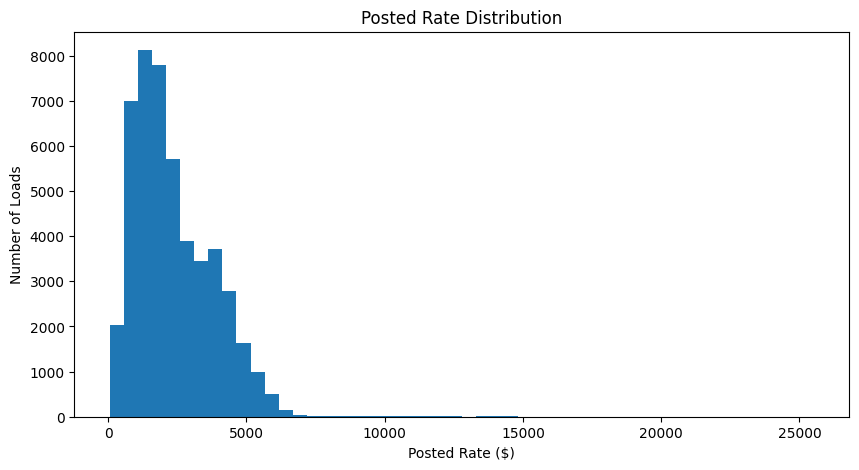

In [21]:
plt.figure(figsize=(10, 5))

plt.hist(train["posted_rate"], bins=50)

plt.title("Posted Rate Distribution")
plt.xlabel("Posted Rate ($)")
plt.ylabel("Number of Loads")

plt.show()

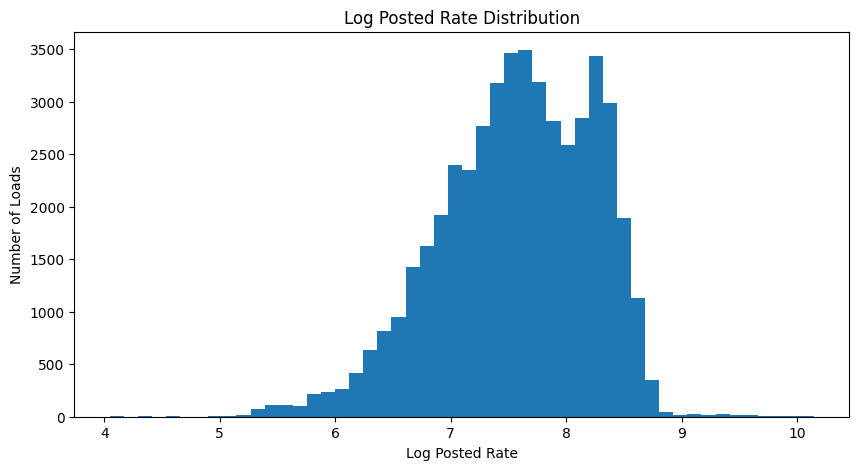

In [22]:
log_rate = np.log(train["posted_rate"])

plt.figure(figsize=(10, 5))

plt.hist(log_rate, bins=50)

plt.title("Log Posted Rate Distribution")
plt.xlabel("Log Posted Rate")
plt.ylabel("Number of Loads")

plt.show()

In [23]:
np.log(train["posted_rate"])

0       6.47
1       6.52
2       7.50
3       7.51
4       7.23
        ... 
47995   8.24
47996   7.07
47997   6.57
47998   8.29
47999   8.57
Name: posted_rate, Length: 48000, dtype: float64

In [24]:
print("Missing weights:", train["weight"].isnull().sum())
print("Negative weights:", (train["weight"] < 0).sum())
print("Zero weights:", (train["weight"] == 0).sum())

Missing weights: 300
Negative weights: 292
Zero weights: 0


In [25]:
train[train["weight"] < 0].head(10)

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
68,TR-000069,Amarillo,Dayton,33.17,-104.37,39.87,-85.63,"1,334.20",Reefer,"-36,559.00",2025-01-01,0.96,2.12,"2,831.27"
204,TR-000205,Fresno,Tucson,33.08,-119.80,30.93,-113.23,496.20,Dry Van,"-26,670.00",2025-01-02,0.97,2.13,"1,046.92"
206,TR-000207,Columbia,Raleigh,34.64,-83.29,35.37,-77.48,411.30,Reefer,"-20,003.00",2025-01-02,0.95,2.32,959.15
225,TR-000226,Greensboro,Lubbock,35.98,-82.78,29.88,-99.85,"1,317.40",Reefer,"-23,981.00",2025-01-02,1.01,2.14,"2,836.00"
376,TR-000377,Madison,Providence,41.70,-89.86,37.37,-69.50,"1,331.10",Dry Van,"-41,397.00",2025-01-03,0.95,1.92,"2,522.54"
446,TR-000447,Albuquerque,Albany,35.40,-109.60,43.97,-71.06,"2,438.30",Reefer,"-37,215.00",2025-01-03,0.97,1.97,"4,841.57"
495,TR-000496,Montgomery,Dayton,31.38,-86.11,39.87,-85.63,715.90,Dry Van,"-31,214.00",2025-01-04,0.85,2.04,"1,473.78"
641,TR-000642,Tulsa,Indianapolis,33.46,-94.79,38.53,-88.86,582.40,Dry Van,"-41,023.00",2025-01-05,0.82,2.23,"1,264.33"
806,TR-000807,Cincinnati,Buffalo,37.16,-86.77,41.68,-78.57,676.10,Dry Van,"-28,320.00",2025-01-06,0.79,1.96,"1,307.76"
1093,TR-001094,Cincinnati,Albany,37.16,-86.77,43.97,-71.06,"1,058.50",Dry Van,"-25,153.00",2025-01-07,0.90,1.81,"1,907.83"


In [26]:
print("Missing distance:", train["distance"].isnull().sum())
print("Negative distance:", (train["distance"] < 0).sum())
print("Zero distance:", (train["distance"] == 0).sum())

Missing distance: 0
Negative distance: 0
Zero distance: 0


In [27]:
train["distance"].describe()

count   48,000.00
mean     1,135.86
std        728.56
min         70.00
25%        550.40
50%        953.30
75%      1,645.53
max      3,439.80
Name: distance, dtype: float64

In [28]:
print("Missing market index:", train["market_index"].isnull().sum())

train["market_index"].describe()

Missing market index: 374


count   47,626.00
mean         1.08
std          0.17
min          0.68
25%          0.95
50%          1.06
75%          1.22
max          1.47
Name: market_index, dtype: float64

In [29]:
print("Missing quote signal:", train["quote_signal"].isnull().sum())

train["quote_signal"].describe()

Missing quote signal: 0


count   48,000.00
mean         2.06
std          0.29
min          0.69
25%          1.89
50%          2.06
75%          2.22
max          3.61
Name: quote_signal, dtype: float64

In [30]:
train["equipment"].value_counts()

equipment
Dry Van    27202
Reefer     12045
Flatbed     8753
Name: count, dtype: int64

In [31]:
validation["equipment"].value_counts()

equipment
Dry Van    6780
Reefer     3051
Flatbed    2169
Name: count, dtype: int64

In [32]:
train["date"] = pd.to_datetime(train["date"])
validation["date"] = pd.to_datetime(validation["date"])

In [33]:
print("Training start:", train["date"].min())
print("Training end:", train["date"].max())

print()

print("Validation start:", validation["date"].min())
print("Validation end:", validation["date"].max())

Training start: 2025-01-01 00:00:00
Training end: 2025-10-31 00:00:00

Validation start: 2025-11-01 00:00:00
Validation end: 2025-12-31 00:00:00


In [34]:
train["month"] = train["date"].dt.month

train["month"].value_counts().sort_index()

month
1     4918
2     4337
3     5036
4     4819
5     4913
6     4783
7     4912
8     4759
9     4670
10    4853
Name: count, dtype: int64

In [35]:
train["rate_per_mile"] = (
    train["posted_rate"] / train["distance"]
)

In [36]:
train["rate_per_mile"].describe()

count   48,000.00
mean         2.22
std          0.58
min          0.33
25%          1.99
50%          2.15
75%          2.34
max         14.13
Name: rate_per_mile, dtype: float64

In [37]:
train.nlargest(
    10,
    "rate_per_mile"
)[
    [
        "pickup",
        "delivery",
        "distance",
        "equipment",
        "posted_rate",
        "rate_per_mile"
    ]
]

,pickup,delivery,distance,equipment,posted_rate,rate_per_mile
22254,Greensboro,Cincinnati,314.70,Reefer,"4,445.23",14.13
36609,Chattanooga,Atlanta,98.40,Reefer,"1,386.42",14.09
870,Tulsa,Baton Rouge,305.60,Reefer,"4,069.24",13.32
17070,Toledo,Dayton,201.50,Flatbed,"2,609.34",12.95
27969,Buffalo,Boston,589.90,Reefer,"7,597.52",12.88
23369,Amarillo,Lubbock,412.40,Flatbed,"5,308.96",12.87
28012,Montgomery,Houston,604.30,Reefer,"7,773.37",12.86
45483,Greensboro,Columbia,153.80,Dry Van,"1,971.21",12.82
1415,Montgomery,Birmingham,198.20,Reefer,"2,509.96",12.66
21968,Jacksonville,Columbia,254.50,Dry Van,"3,220.66",12.65


In [38]:
print("Unique pickup locations:", train["pickup"].nunique())
print("Unique delivery locations:", train["delivery"].nunique())

Unique pickup locations: 64
Unique delivery locations: 64


In [39]:
train["pickup"].value_counts().head(10)

pickup
Oklahoma City    1242
Lexington        1209
Bakersfield      1193
Fort Wayne       1170
Hartford         1150
Richmond         1140
Nashville        1124
Phoenix          1121
Baton Rouge      1115
Mobile           1094
Name: count, dtype: int64

In [40]:
train["delivery"].value_counts().head(10)

delivery
Lexington        1197
Fort Wayne       1176
Baton Rouge      1167
Bakersfield      1156
Hartford         1143
Oklahoma City    1140
Richmond         1109
Atlanta          1096
Phoenix          1090
Mobile           1089
Name: count, dtype: int64

In [41]:
#we have to create a lane Pickup → Delivery

In [42]:
train["lane"] = (
    train["pickup"] + " -> " + train["delivery"]
)

In [43]:
print("Unique lanes:", train["lane"].nunique())

Unique lanes: 4014


In [44]:
train["lane"].value_counts().head(10)

lane
Columbia -> Oklahoma City     39
Phoenix -> Shreveport         39
Lexington -> Atlanta          39
Fort Wayne -> Philadelphia    38
Shreveport -> Hartford        37
Lexington -> Cincinnati       37
Fort Wayne -> Hartford        37
Richmond -> Phoenix           37
Richmond -> Oklahoma City     37
Lexington -> Kansas City      37
Name: count, dtype: int64

In [45]:
columns = [
    "distance",
    "weight",
    "market_index",
    "quote_signal",
    "posted_rate"
]

train[columns].corr()

,distance,weight,market_index,quote_signal,posted_rate
distance,1.00,0.00,-0.00,-0.06,0.91
weight,0.00,1.00,-0.00,0.01,0.03
market_index,-0.00,-0.00,1.00,-0.07,0.03
quote_signal,-0.06,0.01,-0.07,1.00,-0.04
posted_rate,0.91,0.03,0.03,-0.04,1.00


In [46]:
train.groupby("equipment")["posted_rate"].mean()

equipment
Dry Van   2,271.55
Flatbed   2,445.09
Reefer    2,553.64
Name: posted_rate, dtype: float64

In [47]:
train.groupby("equipment")["posted_rate"].median()

equipment
Dry Van   1,953.04
Flatbed   2,076.81
Reefer    2,196.67
Name: posted_rate, dtype: float64

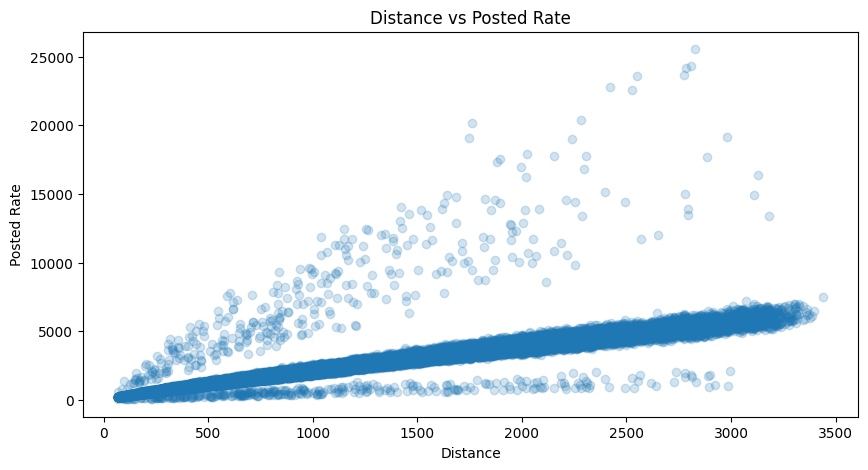

In [48]:
plt.figure(figsize=(10, 5))

plt.scatter(
    train["distance"],
    train["posted_rate"],
    alpha=0.2
)

plt.title("Distance vs Posted Rate")
plt.xlabel("Distance")
plt.ylabel("Posted Rate")

plt.show()

In [49]:
daily_rate = train.groupby("date")["posted_rate"].median()

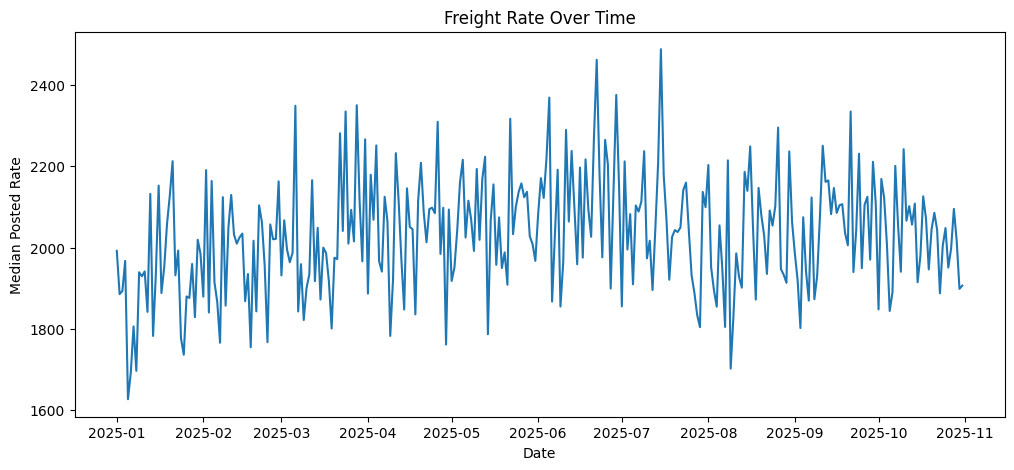

In [50]:
plt.figure(figsize=(12, 5))

plt.plot(daily_rate)

plt.title("Freight Rate Over Time")
plt.xlabel("Date")
plt.ylabel("Median Posted Rate")

plt.show()

In [51]:
columns = [
    "distance",
    "weight",
    "market_index",
    "quote_signal"
]

print("TRAINING")
display(train[columns].mean())

print("VALIDATION")
display(validation[columns].mean())

TRAINING


distance        1,135.86
weight         31,028.84
market_index        1.08
quote_signal        2.06
dtype: float64

VALIDATION


distance        1,141.77
weight         30,506.64
market_index        0.93
quote_signal        2.05
dtype: float64

In [52]:
print("TRAINING MEDIAN")
display(train[columns].median())

print("VALIDATION MEDIAN")
display(validation[columns].median())

TRAINING MEDIAN


distance          953.30
weight         31,436.50
market_index        1.06
quote_signal        2.06
dtype: float64

VALIDATION MEDIAN


distance          953.60
weight         31,193.00
market_index        0.92
quote_signal        2.05
dtype: float64

In [53]:
print("DATA ANALYSIS SUMMARY")
print("=" * 50)

print("Training rows:", len(train))
print("Validation rows:", len(validation))

print("\nData quality:")
print("Missing weight:", train["weight"].isnull().sum())
print("Negative weight:", (train["weight"] < 0).sum())
print("Missing market index:", train["market_index"].isnull().sum())

print("\nTarget:")
print("Average rate:", train["posted_rate"].mean())
print("Median rate:", train["posted_rate"].median())
print("Minimum rate:", train["posted_rate"].min())
print("Maximum rate:", train["posted_rate"].max())

print("\nDates:")
print("Training:", train["date"].min(), "to", train["date"].max())
print("Validation:", validation["date"].min(), "to", validation["date"].max())

print("\nFreight:")
print("Equipment types:", train["equipment"].nunique())
print("Pickup locations:", train["pickup"].nunique())
print("Delivery locations:", train["delivery"].nunique())
print("Lanes:", train["lane"].nunique())

DATA ANALYSIS SUMMARY
Training rows: 48000
Validation rows: 12000

Data quality:
Missing weight: 300
Negative weight: 292
Missing market index: 374

Target:
Average rate: 2373.9806822916667
Median rate: 2030.76
Minimum rate: 57.22
Maximum rate: 25533.0

Dates:
Training: 2025-01-01 00:00:00 to 2025-10-31 00:00:00
Validation: 2025-11-01 00:00:00 to 2025-12-31 00:00:00

Freight:
Equipment types: 3
Pickup locations: 64
Delivery locations: 64
Lanes: 4014


In [54]:

train["lane"] = (
    train["pickup"] + " -> " + train["delivery"]
)

validation["lane"] = (
    validation["pickup"] + " -> " + validation["delivery"]
)



seen = validation["lane"].isin(train["lane"])

print("Validation rows:", len(validation))

print(
    "Rows with known lane:",
    seen.sum()
)

print(
    "Rows with new lane:",
    (~seen).sum()
)

print(
    "Known lane percentage:",
    round(seen.mean() * 100, 2),
    "%"
)

Validation rows: 12000
Rows with known lane: 10539
Rows with new lane: 1461
Known lane percentage: 87.82 %


In [55]:
print(
    "Unique training lanes:",
    train["lane"].nunique()
)

print(
    "Unique validation lanes:",
    validation["lane"].nunique()
)

Unique training lanes: 4014
Unique validation lanes: 4214
